# 08 — Eikonal–angular-spectrum transport through curved interfaces

`PropagationPipeline` carries a field through curved interfaces with the method of the manuscript *Vectorial field transport through general curved interfaces: an eikonal–angular-spectrum formulation*. It is the pipeline's default, `transport="eikonal"`. Between surfaces the field travels as an exact angular spectrum. Across each surface it is carried along its **carrier**, the ray family it declares, by the plane–surface–plane map Φ:

- a point P of a reference plane follows its carrier ray to the surface and refracts there (vector Snell law);
- it continues to P′ on the same geometric plane in the transmitted medium;
- the field arrives multiplied by exp(i k0 ΔS) and the flux factor g, through the continued Fresnel dyadic.

Here ΔS = n_i ℓ_i + n_t ℓ_t is the optical path along the signed legs, g = √(s_iz c_t / (c_i s_tz J)) and J = det DΦ. DΦ is analytic: it comes from the surface Hessian and the carrier's Jacobian (Appendix A). After a refraction the carrier is the refracted ray family (Appendix B).

This notebook runs three of the manuscript's validation geometries at modest size and compares each with its exact reference:

1. the **aplanatic** sphere (Greek *a-planētos*, "not wandering": free of spherical aberration and coma for one conjugate pair), against `MieSphere`;
2. **two aplanatic surfaces** in sequence, against `LayeredSphere`;
3. a circular **cylinder**, a curved but non-spherical (astigmatic) surface, against `InfiniteCylinder`.

The quantity compared is the **first entry**, the Debye term p = 1: the wave transmitted inward through every surface without reflection. This is what the method models, and the references give it exactly. Each case shows the fields first: component intensities, phase on a cyclic scale, the signed E_z on a diverging scale, and polarization ellipses over the intensity. Then it shows the error.

Errors are raw relative complex-field L2 errors on the focal disk, in percent. All lengths are in vacuum wavelengths (λ0 = 1). The guide is [docs/PROPAGATION.md](../../docs/PROPAGATION.md#eikonal-transport).

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from scipy.integrate import simpson
from vecdiff_general.propagation.references import (
    InfiniteCylinder,
    LayeredSphere,
    MieSphere,
)
from vecdiff_general.visualization import plot_focal_polarization

%matplotlib inline
plt.rcParams.update({"image.cmap": "hot", "figure.dpi": 110, "font.size": 10})
host = optics.backend.to_numpy
Frame = optics.geometry.Frame


def region(name, n):
    return optics.media.HomogeneousRegion(name, optics.media.Dielectric(n))


air, glass, dense = region("air", 1.0), region("glass", 1.5), region("dense glass", 2.0)


def converging_beam(max_sine, focus, pupil):
    # The manuscript's Appendix C beam: circular input, transverse spectrum equal
    # to the pupil field, converging toward z = focus. Hard pupil, or the smooth
    # (1 - (u / u_max)²)³.
    profile = (
        optics.fields.profiles.Uniform(max_sine)
        if pupil == "hard"
        else lambda x, y: np.clip(1 - (x**2 + y**2) / max_sine**2, 0, None) ** 3
    )
    return optics.fields.FocusedBeam(
        profile,
        optics.fields.polarization.cartesian(1 / np.sqrt(2), 1j / np.sqrt(2)),
        focal_length=1.0,
        max_sine=max_sine,
        wavelength0=1.0,
        region=air,
        frame=Frame([0, 0, focus]),
        apodization="none",
    )


def focal_plane(z, half_x=5.0, half_y=None, count=120):
    # An even count, so that no sample sits exactly on the image point.
    half_y = half_x if half_y is None else half_y
    u = np.linspace(-half_x, half_x, count)
    v = np.linspace(-half_y, half_y, int(round(count * half_y / half_x)) // 2 * 2)
    return optics.sampling.CartesianGrid(u, v, Frame([0, 0, z]))


def disk_error(field, exact, grid, radius):
    # Raw relative complex L2 error over the disk |(x, y)| <= radius, in percent.
    disk = np.hypot(*np.moveaxis(host(grid.points)[..., :2], -1, 0)) <= radius
    return 100 * np.linalg.norm((field - exact)[disk]) / np.linalg.norm(exact[disk])


def in_wavelengths(ax):
    # The polarization helper labels µm; this notebook uses λ0 = 1.
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
    ax.set(xlabel="x / λ0", ylabel="y / λ0")


def show_fields(grid, field, exact, title):
    # Component intensities (hot), the phase of E_x (cyclic), the signed real part
    # of E_z (diverging) and the error map, all over the same plane.
    u, v = host(grid.u), host(grid.v)
    extent = (u[0], u[-1], v[0], v[-1])
    peak = np.max(np.sum(abs(exact) ** 2, -1))
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.6), layout="constrained")
    for ax, index, name in zip(axes[0], range(3), ("x", "y", "z")):
        image = ax.imshow(abs(field[..., index]) ** 2 / peak, origin="lower",
                          extent=extent, cmap="hot")
        ax.set_title(f"|E_{name}|² (eikonal) / peak |E|²")
        fig.colorbar(image, ax=ax, shrink=0.85)
    bright = abs(field[..., 0]) ** 2 > 1e-3 * peak
    phase = np.where(bright, np.angle(field[..., 0]), np.nan)
    image = axes[1, 0].imshow(phase, origin="lower", extent=extent, cmap="twilight",
                              vmin=-np.pi, vmax=np.pi)
    axes[1, 0].set_title("arg E_x (cyclic; dark where |E_x|² < 1e-3 peak)")
    fig.colorbar(image, ax=axes[1, 0], shrink=0.85, label="rad")
    signed = field[..., 2].real / np.sqrt(peak)
    limit = np.max(abs(signed))
    image = axes[1, 1].imshow(signed, origin="lower", extent=extent, cmap="RdBu_r",
                              norm=TwoSlopeNorm(0, -limit, limit))
    axes[1, 1].set_title("Re E_z / peak |E| (signed)")
    fig.colorbar(image, ax=axes[1, 1], shrink=0.85)
    error = np.linalg.norm(field - exact, axis=-1) / np.sqrt(peak)
    image = axes[1, 2].imshow(error, origin="lower", extent=extent, cmap="hot")
    axes[1, 2].set_title("|E - E_exact| / peak |E_exact|")
    fig.colorbar(image, ax=axes[1, 2], shrink=0.85)
    for ax in axes.flat:
        ax.set(xlabel="x / λ0", ylabel="y / λ0")
    fig.suptitle(title)
    plt.show()


def show_polarization(grid, maps, title):
    # Polarization ellipses over the transverse intensity (hot, logarithmic),
    # eikonal transport beside the exact first entry.
    fig, axes = plt.subplots(1, len(maps), figsize=(5.2 * len(maps), 4.6),
                             layout="constrained")
    centre = np.unravel_index(np.argmax(np.sum(abs(maps[-1][1]) ** 2, -1)),
                              maps[-1][1].shape[:2])
    reference = float(np.sum(abs(maps[-1][1][centre][:2]) ** 2))
    for ax, (name, values) in zip(np.atleast_1d(axes), maps):
        plot_focal_polarization(
            optics.fields.ElectricField(grid, 1.0, values),
            axis=ax, title=name, glyph="ellipse", reference_intensity=reference,
            floor=1e-5, colorbar=False,
        )
        in_wavelengths(ax)
    fig.suptitle(title)
    plt.show()

## 1. The aplanatic sphere

A glass sphere (n = 1.5) of radius R = 100 λ0 is centred at the origin, and its vertex meets the light first. The beam converges toward A = 1.5 R with u_max = 0.4. That is the aplanatic point, whose image B = R / 1.5 lies inside the glass with NA 0.9. The pupil is hard, as in the manuscript's Table 1.

A `SphericalCap` is a graph and ends at its equator, at 56.3° of incidence here. The reference fan therefore rolls the carried rays off between 50° and 56° (`reference_fans`); a hard cut at the fan's edge would diffract. The beam brings its own carrier, the rays toward A, and the system is a surface of revolution about the beam's axis. Each azimuthal order is therefore carried on one meridian (Latin *meridianus*, of midday: a half-plane through the axis), with Hankel spectra, rather than on a 2D lattice.

In [2]:
R = 100.0
beam = converging_beam(0.4, 1.5 * R, "hard")
sphere = optics.surfaces.SphericalCap(R, Frame([0, 0, -R]))
pipeline = optics.propagation.PropagationPipeline(
    (optics.system.DielectricInterface(sphere, air, glass),),
    reference_fans=((50.0, 56.0),),
)
start = perf_counter()
solution = pipeline.solve(beam)
plane = focal_plane(R / 1.5)
field = host(solution.evaluate(plane).electric.values)
seconds = perf_counter() - start
report = solution.interactions[0]
start = perf_counter()
mie = MieSphere(beam, optics.volumes.SphereVolume([0, 0, 0], R), glass)
exact = host(mie.evaluate(plane, term=1, side="interior").electric.values)
total = host(mie.evaluate(plane, side="interior").electric.values)
reference_seconds = perf_counter() - start
print(f"eikonal transport: {seconds:.2f} s, azimuthal orders {report.azimuthal_orders}, "
      f"unsupported incident amplitude {report.unsupported_relative_amplitude:.2e}")
print(f"Mie reference: {reference_seconds:.1f} s, {mie.order} multipoles")
print(f"error against the first entry (Debye p = 1): {disk_error(field, exact, plane, 5):.4f} %")
print(f"error against the full Mie field:            {disk_error(field, total, plane, 5):.4f} %")

eikonal transport: 0.17 s, azimuthal orders (1,), unsupported incident amplitude 5.19e-02
Mie reference: 82.6 s, 692 multipoles
error against the first entry (Debye p = 1): 1.5194 %
error against the full Mie field:            3.8814 %


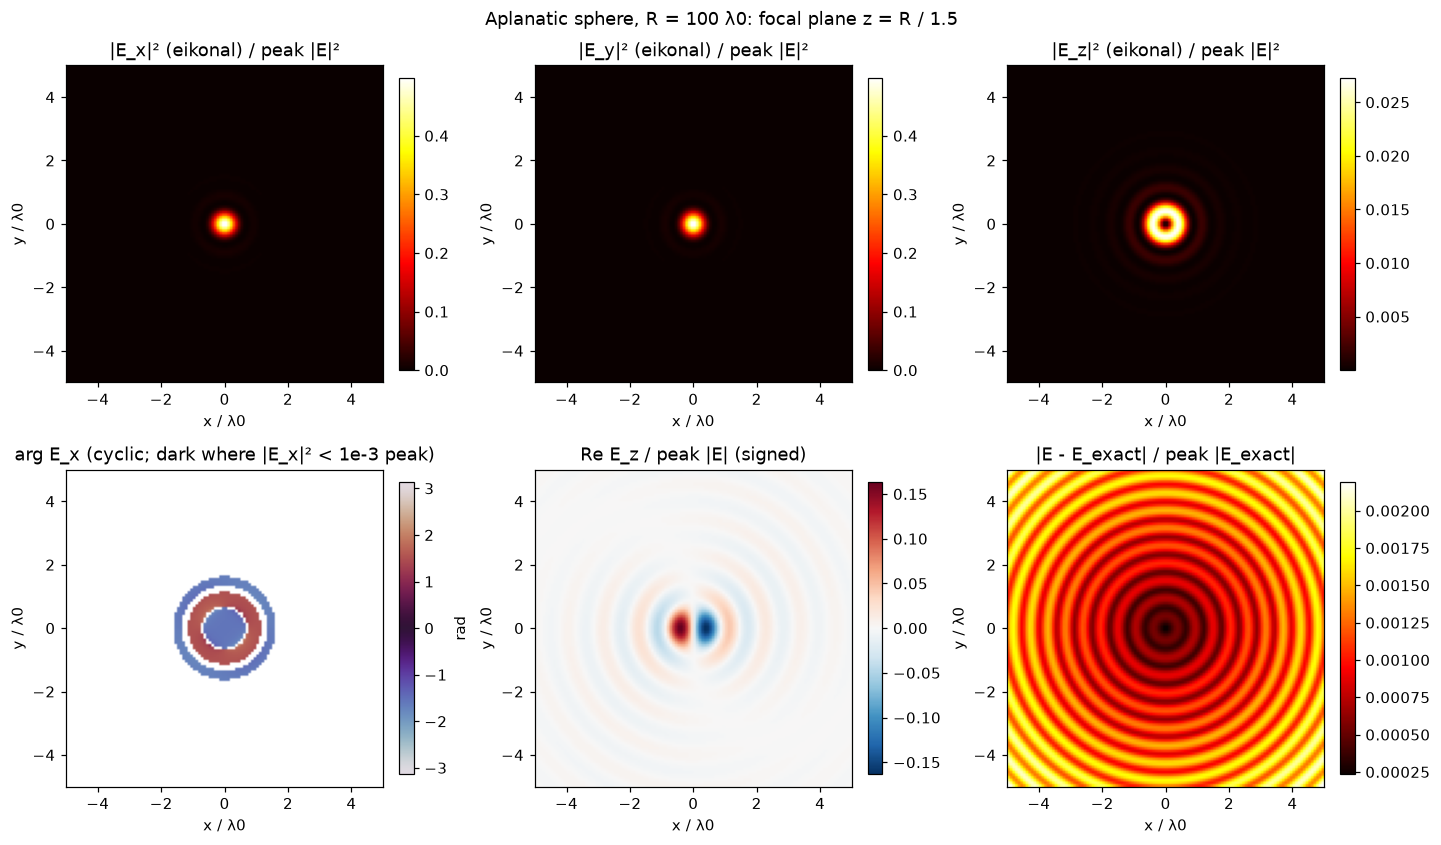

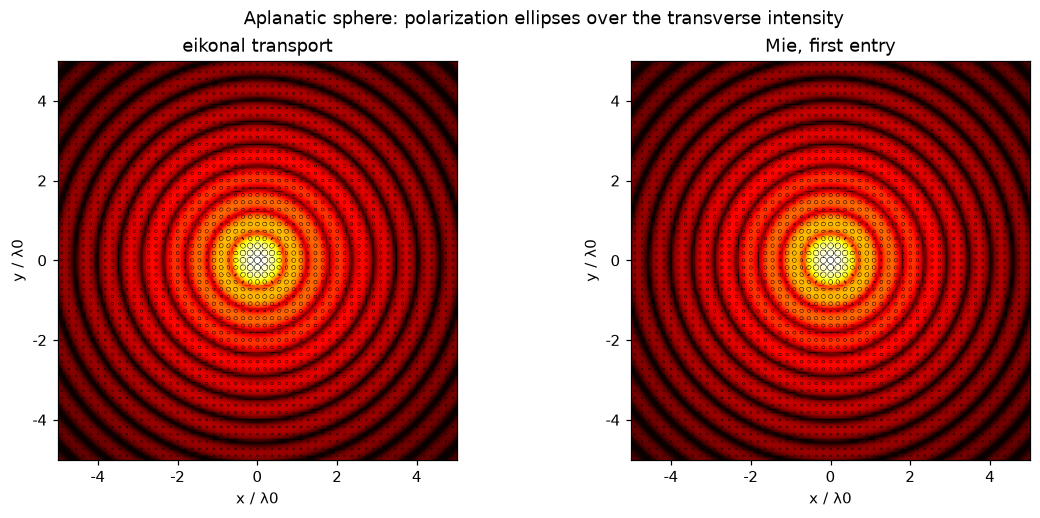

In [3]:
show_fields(plane, field, exact, f"Aplanatic sphere, R = {R:g} λ0: focal plane z = R / 1.5")
show_polarization(plane, [("eikonal transport", field), ("Mie, first entry", exact)],
                  "Aplanatic sphere: polarization ellipses over the transverse intensity")

Circular input stays circular: the transverse ellipses are circles across the focal plane. The longitudinal field E_z forms a ring, up to 2.7 % of the peak intensity, with a zero on the axis, and its real part changes sign across the axis. The error grows outward in rings and is smallest on the axis. The outer rings are where the hard pupil's edge diffraction carries more of the field, and where the method's leading-order transfer falls short of the curved-boundary Maxwell problem.

### The error law

The method's error falls as 1 / (R / λ0). The manuscript gives about 1.42 / (R / λ0) % for this hard-pupil geometry from R ≈ 150 λ0. With the smooth pupil, (1 − (u / u_max)²)³, the edge goes and only the curvature term remains. The sweep below uses the same disk error on 161 radii of the focal plane (Eq. 8.2, with Simpson's rule in ρ).

56 solutions and references in 55 s


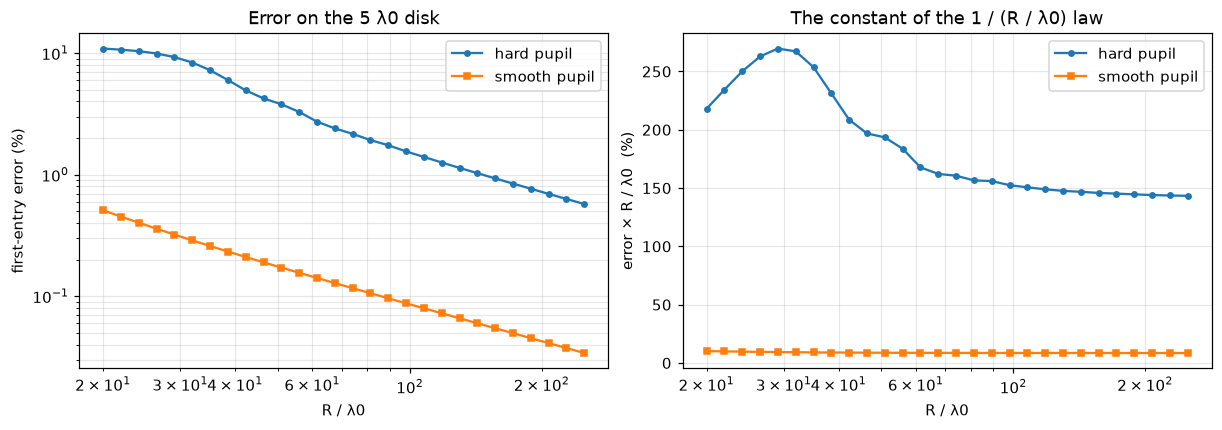

hard pupil, error × R at the largest radius: 143.3 % (manuscript: about 142 for R >= 150 λ0)


In [4]:
radii = np.geomspace(20, 250, 28)
rho = np.linspace(0, 5, 161)
law = {"hard": [], "smooth": []}
start = perf_counter()
for radius in radii:
    line = optics.sampling.PointGrid(np.c_[rho, 0 * rho, np.full(rho.size, radius / 1.5)])
    cap = optics.surfaces.SphericalCap(radius, Frame([0, 0, -radius]))
    for pupil in law:
        incident = converging_beam(0.4, 1.5 * radius, pupil)
        carried = optics.propagation.PropagationPipeline(
            (optics.system.DielectricInterface(cap, air, glass),),
            reference_fans=((50.0, 56.0),),
        ).solve(incident)
        values = host(carried.evaluate(line).electric.values)
        reference = host(
            MieSphere(incident, optics.volumes.SphereVolume([0, 0, 0], radius), glass)
            .evaluate(line, term=1, side="interior").electric.values
        )
        norm = lambda E: simpson(rho * np.sum(abs(E) ** 2, -1), x=rho)
        law[pupil].append(100 * np.sqrt(norm(values - reference) / norm(reference)))
print(f"{2 * len(radii)} solutions and references in {perf_counter() - start:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for pupil, marker in (("hard", "o"), ("smooth", "s")):
    error = np.array(law[pupil])
    axes[0].loglog(radii, error, marker + "-", ms=3.5, label=f"{pupil} pupil")
    axes[1].semilogx(radii, error * radii, marker + "-", ms=3.5, label=f"{pupil} pupil")
axes[0].set(xlabel="R / λ0", ylabel="first-entry error (%)", title="Error on the 5 λ0 disk")
axes[1].set(xlabel="R / λ0", ylabel="error × R / λ0  (%)",
            title="The constant of the 1 / (R / λ0) law")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.show()
print("hard pupil, error × R at the largest radius: "
      f"{law['hard'][-1] * radii[-1]:.1f} % (manuscript: about 142 for R >= 150 λ0)")

## 2. Two aplanatic surfaces

A glass shell (n = 1.5) between R2 = R1 / 2 and R1 = 100 λ0 holds a dense core (n = 2). The beam converges toward 1.5 R1 with u_max = 0.4.

- Both refractions are aplanatic. The first images A at R1 / 1.5, which is also the aplanatic point of the inner surface.
- The stigmatic image lies at 0.375 R1 in the core, with NA 1.6.
- Incidence reaches 36.9° and 53.1°: the hard pupil's marginal ray meets the inner surface exactly at its equator.

The method follows the manuscript's prescription for a sequence:
1. the leg at the outer surface;
2. the exact angular spectrum through the shell;
3. the full field on the second reference plane;
4. the leg at the inner surface, now along the **refracted** ray family (`RefractedRays`, Appendix B);
5. the angular spectrum in the core.

Both surfaces are closed spheres (`surfaces.Sphere`), so the hard pupil's edge tails can enter beyond the caps' equators, as in the archived code. The fans roll off from 72° to 80°.

In [5]:
R1, R2 = R, R / 2
beam2 = converging_beam(0.4, 1.5 * R1, "hard")
shells = (
    optics.system.DielectricInterface(optics.surfaces.Sphere(R1, Frame([0, 0, -R1])), air, glass),
    optics.system.DielectricInterface(optics.surfaces.Sphere(R2, Frame([0, 0, -R2])), glass, dense),
)
pipeline2 = optics.propagation.PropagationPipeline(shells, reference_fans=((72.0, 80.0), (72.0, 80.0)))
start = perf_counter()
solution2 = pipeline2.solve(beam2)
plane2 = focal_plane(0.375 * R1)
field2 = host(solution2.evaluate(plane2).electric.values)
seconds = perf_counter() - start
start = perf_counter()
layered = LayeredSphere(
    beam2,
    (optics.volumes.SphereVolume([0, 0, 0], R1), optics.volumes.SphereVolume([0, 0, 0], R2)),
    (glass, dense),
)
exact2 = host(layered.evaluate(plane2, term=1, side="interior").electric.values)
total2 = host(layered.evaluate(plane2, side="interior").electric.values)
reference_seconds = perf_counter() - start
print(f"eikonal transport through both surfaces: {seconds:.2f} s")
for index, report in enumerate(solution2.interactions, 1):
    print(f"  surface {index}: unsupported incident amplitude {report.unsupported_relative_amplitude:.2e}")
print(f"LayeredSphere reference: {reference_seconds:.1f} s")
print(f"error against the first entry through both surfaces: {disk_error(field2, exact2, plane2, 5):.3f} %")
print(f"error against the full layered solution:             {disk_error(field2, total2, plane2, 5):.3f} %")

eikonal transport through both surfaces: 0.48 s
  surface 1: unsupported incident amplitude 3.94e-02
  surface 2: unsupported incident amplitude 7.38e-02
LayeredSphere reference: 3.5 s
error against the first entry through both surfaces: 11.896 %
error against the full layered solution:             12.915 %


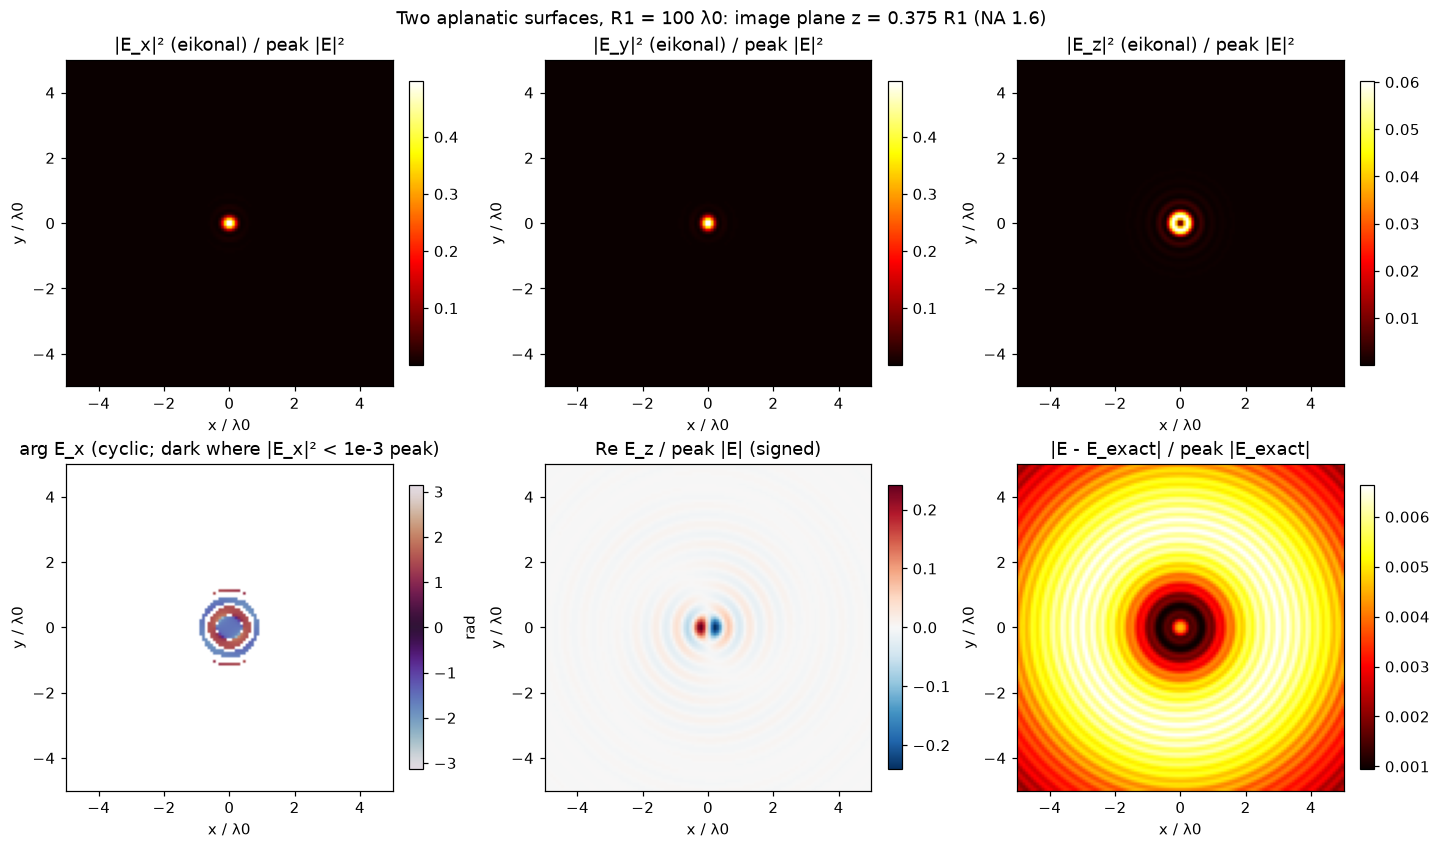

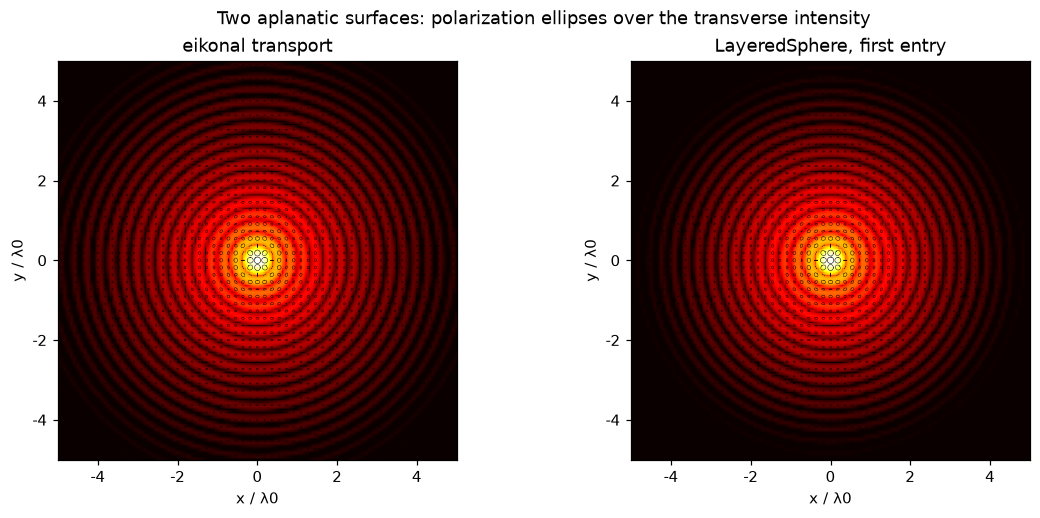

In [6]:
show_fields(plane2, field2, exact2, f"Two aplanatic surfaces, R1 = {R1:g} λ0: image plane z = 0.375 R1 (NA 1.6)")
show_polarization(plane2, [("eikonal transport", field2), ("LayeredSphere, first entry", exact2)],
                  "Two aplanatic surfaces: polarization ellipses over the transverse intensity")

At NA 1.6 the focus is tighter than the single sphere's, and E_z rises to 6 % of the peak intensity. The error is largest in a broad annulus beyond about 2 λ0, where the hard pupil's edge diffraction lives; the edge dominates the error at this size. The archived results (the manuscript's Table 5) give 11.8 % at R1 = 100 λ0 with vertex planes, falling to 0.883 % at 1000 λ0. Placing the reference planes at the depths where the marginal ray meets each surface (`reference_planes`) lowers the archive's 11.8 % to 4.54 %.

## 3. A circular cylinder

An infinite glass cylinder (axis y, n = 1.5) of radius R = 30 λ0 is curved only in the xz-plane: a macroscopic astigmatic interface. The beam converges toward z = 1.5 R with u_max = 0.25, the aplanatic conjugate in the xz-plane.

- Meridional rays meet at z = 2R / 3.
- Along y the interface is flat at the vertex, and the beam keeps converging toward 2.75 R.
- The focal plane therefore holds a **line focus** along y, about 0.6 R long.

There is no rotational symmetry, so the field is carried on a 2D lattice at λ0 / 3 with the full 2 × 2 Jacobian. The fan is the archive's: transverse sine up to 1.9 u_max, tapered from 1.7, incidence up to 85° from 78°, and transmitted rays with s_t,z > 0.05.

In [7]:
from vecdiff_general.propagation.eikonal import ray_weights

Rc, umax = 30.0, 0.25
beam3 = converging_beam(umax, 1.5 * Rc, "hard")


def archive_fan(rays):
    s = host(rays.incident)
    t = np.clip((np.hypot(s[:, 0], s[:, 1]) - 1.7 * umax) / (0.2 * umax), 0, 1)
    weight = 0.5 * (1 + np.cos(np.pi * t)) * host(ray_weights((78.0, 85.0), rays))
    return weight * (host(rays.transmitted)[:, 2] > 0.05)


axis = (np.arange(356) - 356 // 2) / 3
lattice = optics.sampling.CartesianGrid(axis, axis, Frame([0, 0, -Rc]))
sampled = beam3.evaluate(lattice, method="nufft").electric.values[..., :2]
spectrum = optics.fields.angular_spectrum(
    optics.fields.TransverseElectricField(lattice, 1.0, sampled), air, evanescent="discard"
)
cylinder = optics.surfaces.CylindricalCap(Rc, Frame([0, 0, -Rc]))
pipeline3 = optics.propagation.PropagationPipeline(
    (optics.system.DielectricInterface(cylinder, air, glass),), reference_fans=(archive_fan,)
)
start = perf_counter()
solution3 = pipeline3.solve(spectrum, carrier=beam3.carrier)
plane3 = focal_plane(Rc / 1.5, half_x=3.5, half_y=0.4 * Rc, count=120)
field3 = host(solution3.evaluate(plane3, method="nufft").electric.values)
seconds = perf_counter() - start
start = perf_counter()
reference3 = InfiniteCylinder(
    beam3, optics.volumes.CylinderVolume([0, 0, 0], [0, 1, 0], Rc), glass, reach=0.4 * Rc + 1
)
exact3 = host(reference3.evaluate(plane3, term=1, side="interior").electric.values)
reference_seconds = perf_counter() - start
print(f"eikonal transport on a {len(axis)}² lattice: {seconds:.1f} s; "
      f"unsupported amplitude {solution3.interactions[0].unsupported_relative_amplitude:.2e}")
print(f"InfiniteCylinder reference: {reference_seconds:.1f} s, {len(reference3.axial)} axial nodes")
print(f"error on the 3.5 λ0 disk: {disk_error(field3, exact3, plane3, 3.5):.4f} %")

eikonal transport on a 356² lattice: 15.6 s; unsupported amplitude 4.58e-02
InfiniteCylinder reference: 1.9 s, 153 axial nodes
error on the 3.5 λ0 disk: 0.8089 %


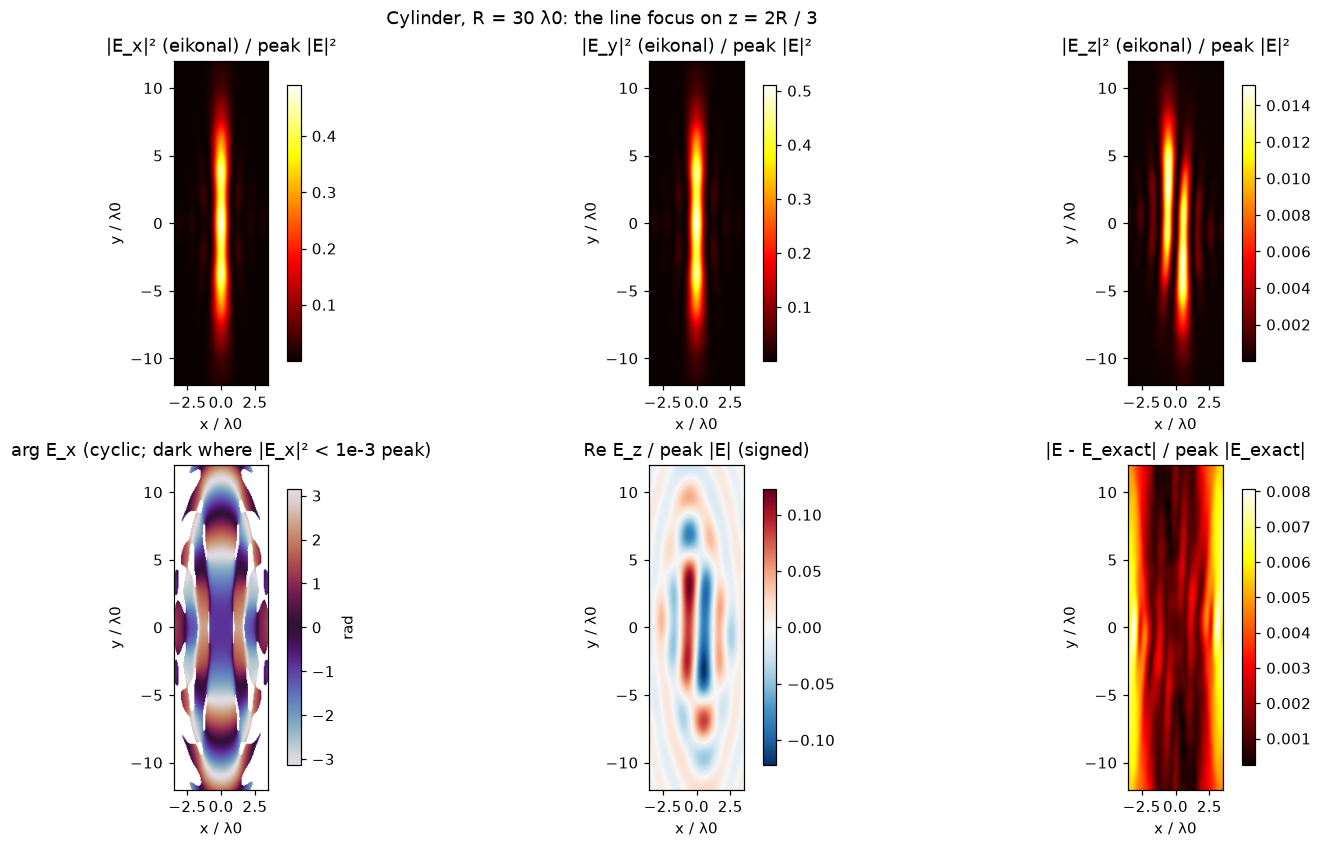

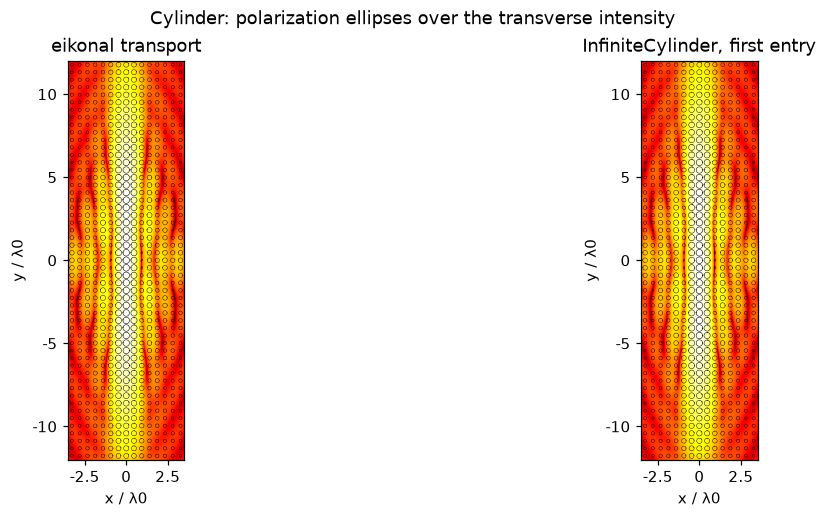

In [8]:
show_fields(plane3, field3, exact3, f"Cylinder, R = {Rc:g} λ0: the line focus on z = 2R / 3")
show_polarization(plane3, [("eikonal transport", field3), ("InfiniteCylinder, first entry", exact3)],
                  "Cylinder: polarization ellipses over the transverse intensity")

The line focus runs along y over about 0.6 R. Along y the phase of E_x curves, because in that direction the beam still converges toward 2.75 R. E_z changes sign across the line. The error is smallest on the line focus and grows toward the edges of the window in x. Over the 3.5 λ0 disk it is the archive's 0.81 % at this size, and it falls to 0.193 % at 100 λ0 (`test_eikonal_regression.py`, opt-in with `VECDIFF_SLOW=1`).

## What the method leaves out

The method computes the first entry. The internal reflections that the full references add, visible in the "full" errors above, are outside a single-pass method; so are the critical-angle and creeping waves.

Its error is the leading-order transfer's error at each surface. It falls as 1 / (R / λ0), and a hard pupil's edge adds to it. A taper of the reference fan and reference planes at the marginal ray's depth reduce that part. The guide's regression table lists every handoff row at 1000 λ0 and explains the rows that differ from it.